In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset

In [2]:
df = pd.read_csv("../data/processed/smartcart_customers_cleaned.csv")

In [3]:
df.shape

(2236, 18)

In [4]:
X = df

## Scaling data

In [5]:
scale = StandardScaler()
X_scaled = scale.fit_transform(X)

In [6]:
pca = PCA(n_components = 3)

X_pca = pca.fit_transform(X_scaled)

In [7]:
pca.explained_variance_ratio_

array([0.22945082, 0.11114749, 0.1020684 ])

Text(0.5, 0.92, '3D Visualization')

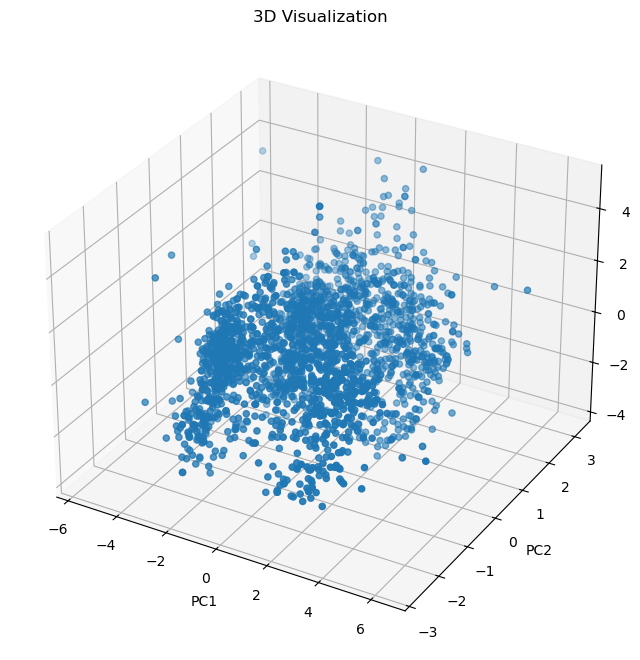

In [8]:
fig = plt.figure(figsize=(8, 12))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2])

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D Visualization")

# Analyze K value

## 1. Elbow Method

In [9]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [10]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [11]:
knee = KneeLocator(range(1, 11), wcss, curve = "convex", direction = "decreasing")
print("Optimal K: ",knee.elbow)

Optimal K:  4


<Axes: >

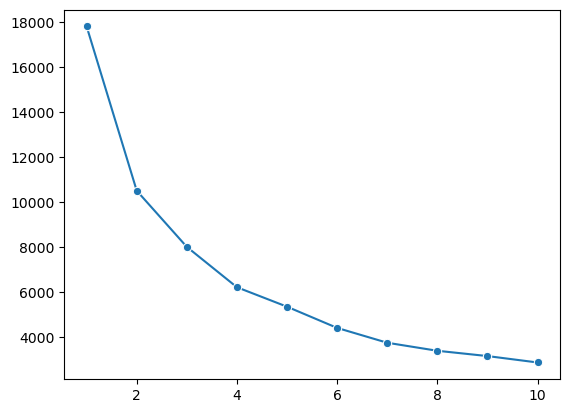

In [12]:
# lineplot
sns.lineplot(x = range(1, 11), y = wcss, marker = "o")

## 2. Silhouette Score

In [13]:
from sklearn.metrics import silhouette_score

scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

<Axes: >

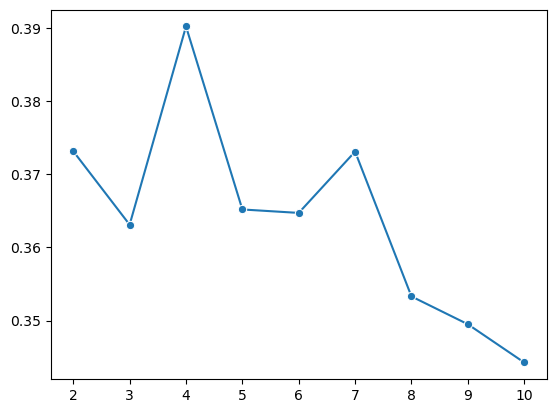

In [14]:
sns.lineplot(x = range(2, 11), y = scores, marker = "o")

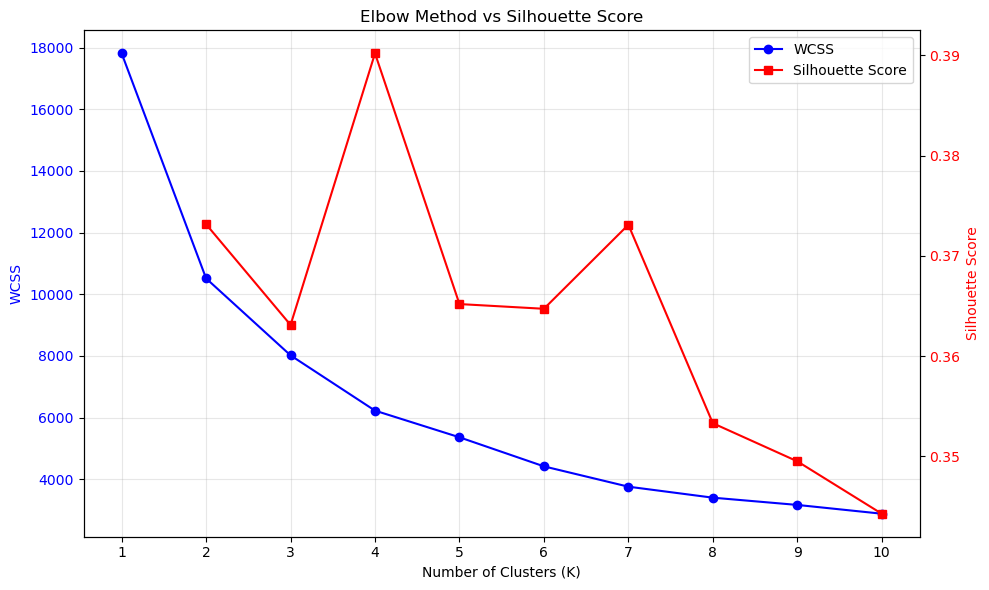

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Elbow Method (Left Y-axis)
ax1.plot(
    range(1, 11), wcss,
    marker="o", color="blue", label="WCSS"
)
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("WCSS", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# Silhouette Score (Right Y-axis)
ax2 = ax1.twinx()

ax2.plot(
    range(2, 11), scores,
    marker="s", color="red", label="Silhouette Score"
)
ax2.set_ylabel("Silhouette Score", color="red")
ax2.tick_params(axis="y", labelcolor="red")

# Title and legend
plt.title("Elbow Method vs Silhouette Score")
ax1.set_xticks(range(1, 11))
ax1.grid(True, alpha=0.3)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

# Apply Clustering Models

## 1. KMeans Cluster

In [16]:
kmeans = KMeans(n_clusters = 4, random_state = 42)
labels_km = kmeans.fit_predict(X_pca)

Text(0.5, 0.92, '3D Visualization')

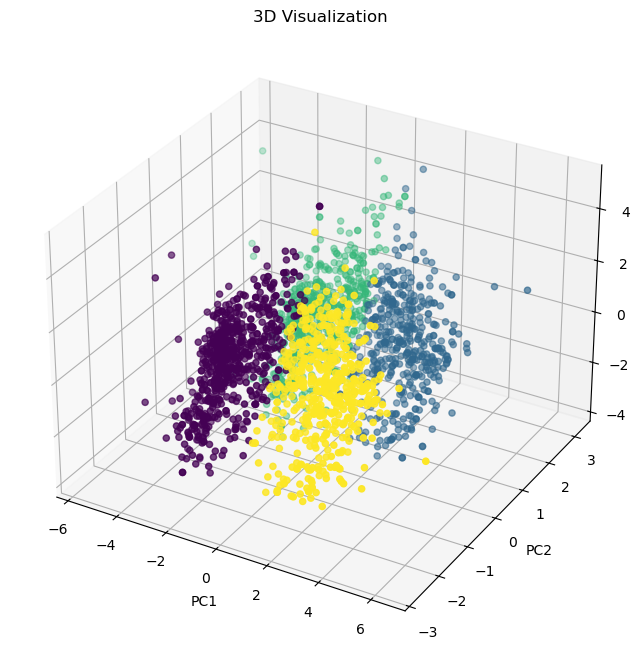

In [17]:
fig = plt.figure(figsize=(8, 12))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c = labels_km)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D Visualization")

<Axes: >

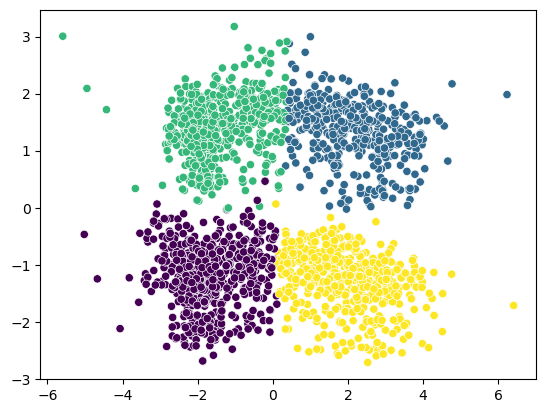

In [18]:
sns.scatterplot(x = X_pca[:, 0], y = X_pca[:, 1], c = labels_km)


## 2. Agglomerative Cluster

In [19]:
from sklearn.cluster import AgglomerativeClustering

aglo_clus = AgglomerativeClustering(n_clusters = 4, linkage = "ward")

labels_aglo = aglo_clus.fit_predict(X_pca)

Text(0.5, 0.92, '3D Visualization')

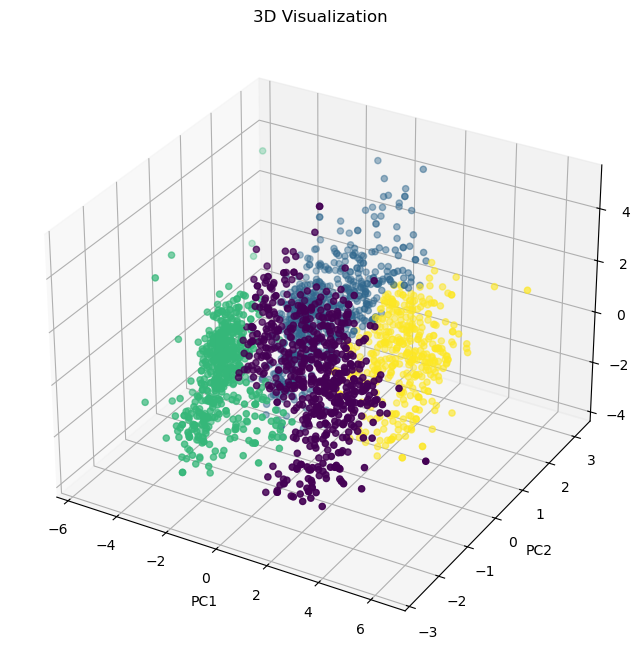

In [20]:
fig = plt.figure(figsize=(8, 12))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c = labels_aglo)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D Visualization")

<Axes: >

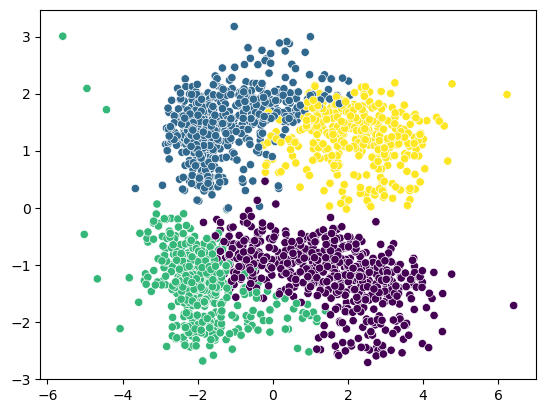

In [21]:
sns.scatterplot(x = X_pca[:, 0], y = X_pca[:, 1], c = labels_aglo)


## Evaluate

In [22]:
from sklearn.metrics import silhouette_score

km_sil_score = silhouette_score(X_pca, labels_km)
aglo_sil_score = silhouette_score(X_pca, labels_aglo)

In [23]:
print("KMeans Silhouette Score: ", km_sil_score)
print("Agglomerative Silhouette Score: ", aglo_sil_score)

KMeans Silhouette Score:  0.3902048592598589
Agglomerative Silhouette Score:  0.3471891479701032


## Characterization of Clustering

In [24]:
df["Labels"] = labels_km

In [25]:
df.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Customer_Tenure,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Marital_Status_Partner,Marital_Status_Previously_Married,Marital_Status_Single,Marital_Status_Unknown,Labels
0,58138.0,58,3,8,10,4,7,57,663,1617,0,1,0,0,0,0,1,0,3
1,46344.0,38,2,1,1,2,5,60,113,27,2,1,0,0,0,0,1,0,0
2,71613.0,26,1,8,2,10,4,49,312,776,0,1,0,0,1,0,0,0,3
3,26646.0,26,2,2,0,4,6,30,139,53,1,1,0,0,1,0,0,0,0
4,58293.0,94,5,5,3,6,5,33,161,422,1,0,1,0,1,0,0,0,2


<Axes: xlabel='Labels', ylabel='count'>

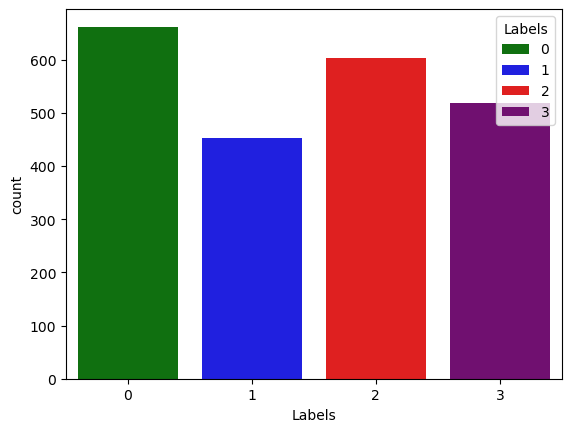

In [26]:
pal = ["green", "blue", "red", "purple"]

sns.countplot( x = df["Labels"], palette = pal, hue = df["Labels"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

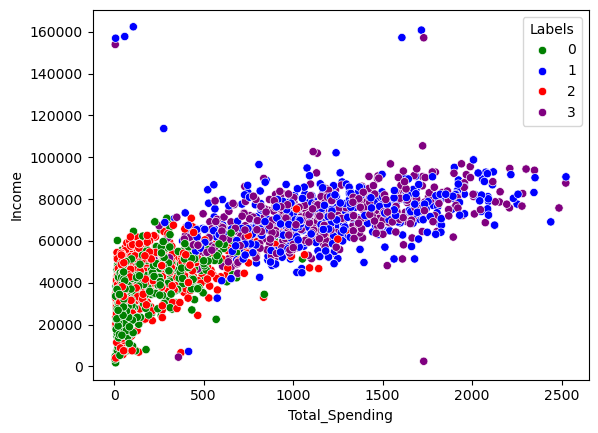

In [27]:
# Income & Total_Spending patterns
sns.scatterplot(x = df["Total_Spending"], y = df["Income"], palette = pal, hue = df["Labels"])

## Cluster Summary

In [28]:
cluster_summary = df.groupby("Labels").mean()
print(cluster_summary)

              Income    Recency  NumDealsPurchases  NumWebPurchases  \
Labels                                                                
0       35083.802115  49.811178           2.512085         2.711480   
1       71345.471239  48.787611           2.004425         5.765487   
2       39878.951159  47.663907           2.647351         2.956954   
3       70667.043436  50.208494           1.994208         5.700772   

        NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth        Age  \
Labels                                                                         
0                  0.714502           3.584592           6.690332  42.308157   
1                  5.108407           8.592920           3.743363  48.449115   
2                  0.908940           3.897351           6.418874  44.725166   
3                  5.065637           8.393822           3.658301  46.191120   

        Customer_Tenure  Total_Spending  Total_Children  Education_Graduate  \
Labels       

## Segment Names

| Cluster | Segment name | Distinguishing pattern |
|---|---|---|
| 0 | Selective Value Shoppers | Lowest income (35,084) and spending (152); most monthly web visits (6.7) |
| 1 | Established Premium Buyers | Highest spending (1,188), store purchases (8.6), and customer tenure (375) |
| 2 | Deal-Seeking Family Shoppers | Most deal purchases (2.65) and children (1.32), with modest spending (190) |
| 3 | Affluent Multi-Channel Shoppers | High income (70,667) and spending (1,163), with frequent web, catalog, and store purchases |

Clusters 1 and 3 have very similar shopping profiles. Their names highlight small differences in the averages rather than a strong behavioral separation.

In [ ]:
segment_names = {
    0: "Selective Value Shoppers",
    1: "Established Premium Buyers",
    2: "Deal-Seeking Family Shoppers",
    3: "Affluent Multi-Channel Shoppers",
}
df["Segment"] = df["Labels"].map(segment_names)

In [30]:
import joblib

joblib.dump(
    kmeans,
    "../models/kmeans_model.pkl"
)
joblib.dump(scale, "../models/standard_scaler.pkl")
joblib.dump(pca, "../models/pca.pkl")

['../models/kmeans_model.pkl']